In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("../data/city_day.csv")

In [3]:
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory


In [4]:
## Data Inspection

In [5]:
df.columns

Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='str')

In [6]:
df.head(10)

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN
5,Ahmedabad,2015-01-06,NaN,NaN,45.41,38.48,81.50,NaN,45.41,45.76,46.51,5.42,10.83,1.93,NaN,NaN
6,Ahmedabad,2015-01-07,NaN,NaN,112.16,40.62,130.77,NaN,112.16,32.28,33.47,0.00,0.00,0.00,NaN,NaN
7,Ahmedabad,2015-01-08,NaN,NaN,80.87,36.74,96.75,NaN,80.87,38.54,31.89,0.00,0.00,0.00,NaN,NaN
8,Ahmedabad,2015-01-09,NaN,NaN,29.16,31.00,48.00,NaN,29.16,58.68,25.75,0.00,0.00,0.00,NaN,NaN
9,Ahmedabad,2015-01-10,NaN,NaN,NaN,7.04,0.00,NaN,NaN,8.29,4.55,0.00,0.00,0.00,NaN,NaN


In [7]:
df.tail(10)

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
29521,Visakhapatnam,2020-06-22,33.17,108.22,5.58,42.45,27.06,13.70,0.73,13.65,34.85,3.99,10.24,2.32,95.0,Satisfactory
29522,Visakhapatnam,2020-06-23,25.40,83.38,2.76,34.09,19.92,13.13,0.54,10.40,43.27,2.88,12.03,1.33,100.0,Satisfactory
29523,Visakhapatnam,2020-06-24,34.36,90.90,1.22,23.38,13.12,14.45,0.56,10.92,35.12,2.99,3.15,1.60,86.0,Satisfactory
29524,Visakhapatnam,2020-06-25,13.45,58.54,2.30,21.60,13.09,12.27,0.41,8.19,29.38,1.28,5.64,0.92,77.0,Satisfactory
29525,Visakhapatnam,2020-06-26,7.63,32.27,5.91,23.27,17.19,11.15,0.46,6.87,19.90,1.45,5.37,1.45,47.0,Good
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory
29530,Visakhapatnam,2020-07-01,15.00,66.00,0.40,26.85,14.05,5.20,0.59,2.10,17.05,NaN,NaN,NaN,50.0,Good


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


In [9]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [10]:
df.shape

(29531, 16)

In [11]:
df.dtypes

City              str
Date              str
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket        str
dtype: object

In [12]:
#Data Cleaning

In [13]:
df.isnull().sum()  #This will display the no of rows with missing values

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [14]:
df = df.dropna(subset=["AQI"]).reset_index(drop=True)
print(df.shape)  # expect (24850, 16)


(24850, 16)


In [15]:
df.isnull().sum()

City              0
Date              0
PM2.5           678
PM10           7086
NO              387
NO2             391
NOx            1857
NH3            6536
CO              445
SO2             605
O3              807
Benzene        3535
Toluene        5826
Xylene        15372
AQI               0
AQI_Bucket        0
dtype: int64

In [16]:
#Q1. Which 5 cities have the worst average AQI?

In [17]:
Five_worst_city=df.groupby("City")["AQI"].mean().sort_values(ascending=False).head(5)

In [18]:
Five_worst_city

City
Ahmedabad    452.122939
Delhi        259.487744
Patna        240.782042
Gurugram     225.123882
Lucknow      217.973059
Name: AQI, dtype: float64

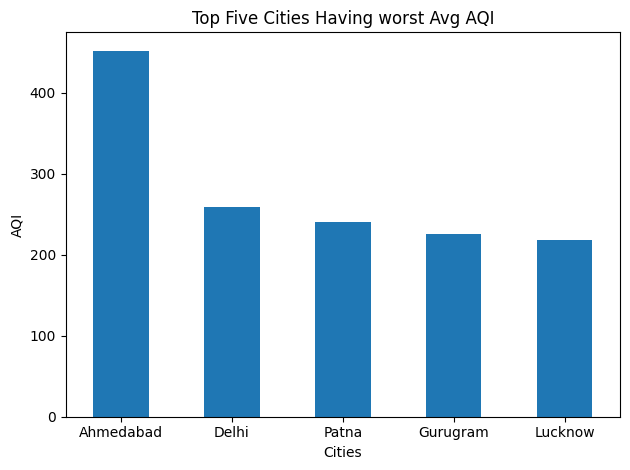

In [19]:
Five_worst_city.plot(kind="bar")
plt.title("Top Five Cities Having worst Avg AQI")
plt.xlabel("Cities")
plt.ylabel("AQI")
plt.xticks(rotation=0)
plt.tight_layout()  
plt.show()

In [20]:
#Q2. Which 5 cities have the best average AQI?

In [21]:
Five_best_city=df.groupby("City")["AQI"].mean().sort_values().head(5)

In [22]:
Five_best_city

City
Aizawl                34.765766
Shillong              53.795122
Coimbatore            73.023256
Thiruvananthapuram    75.878327
Ernakulam             92.359477
Name: AQI, dtype: float64

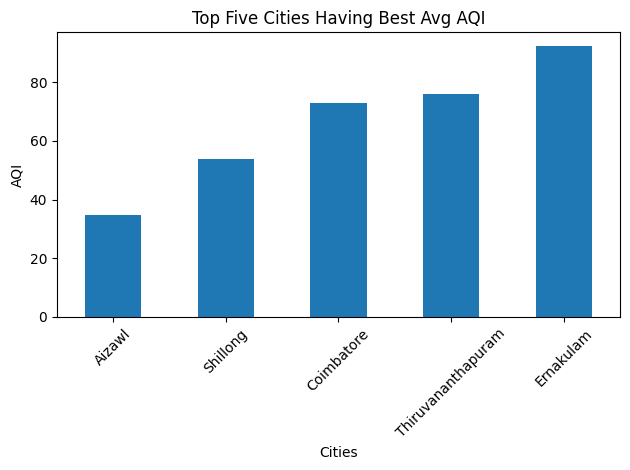

In [23]:
Five_best_city.plot(kind="bar")
plt.title("Top Five Cities Having Best Avg AQI")   
plt.xlabel("Cities")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()   
plt.show()

In [24]:
#Q3. Which pollutant is most strongly associated with AQI?

In [25]:
Strong_pollutant=df[["PM2.5","PM10","NO","NO2","NOx","NH3","CO","SO2","O3","Benzene","Toluene","Xylene","AQI"]].corr()["AQI"].drop("AQI").abs().sort_values(ascending=False).head(1)

In [26]:
Strong_pollutant

PM10    0.803313
Name: AQI, dtype: float64

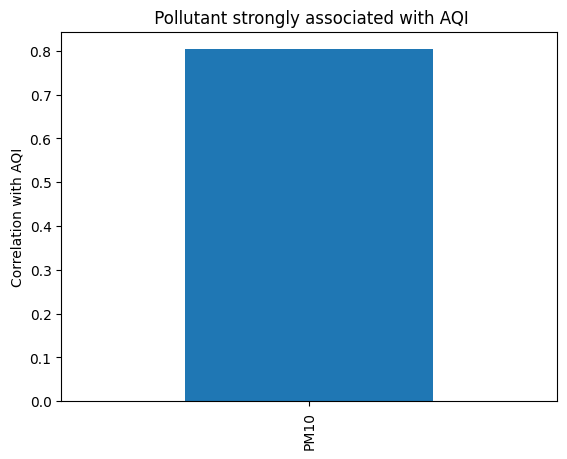

In [27]:
Strong_pollutant.plot(kind="bar")
plt.title(" Pollutant strongly associated with AQI")
plt.ylabel("Correlation with AQI")   # CHANGED: was "AQI"
plt.show()

In [28]:
pollutants = ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3", "AQI"]
corr = df[pollutants].corr()
corr["AQI"].sort_values(ascending=False)

AQI      1.000000
PM10     0.803313
CO       0.683346
PM2.5    0.659181
NO2      0.537071
SO2      0.490586
O3       0.198991
Name: AQI, dtype: float64

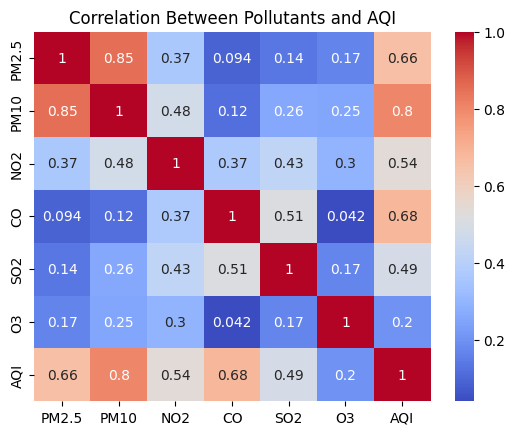

In [29]:
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.title("Correlation Between Pollutants and AQI")
plt.show()

In [30]:
#Q4. Does a high PM2.5 level always mean a high AQI?

<Axes: xlabel='PM2.5', ylabel='AQI'>

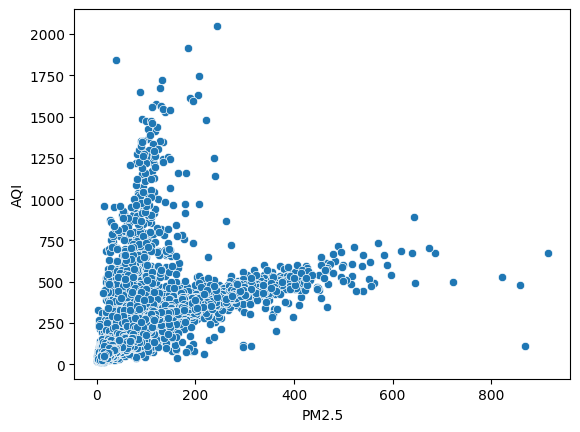

In [31]:
sns.scatterplot(data=df, x="PM2.5", y="AQI")

In [32]:
#Q5. Which city experiences the most extreme pollution levels?

In [33]:
df.groupby("City")["AQI"].max().sort_values(ascending=False).head(1)

City
Ahmedabad    2049.0
Name: AQI, dtype: float64

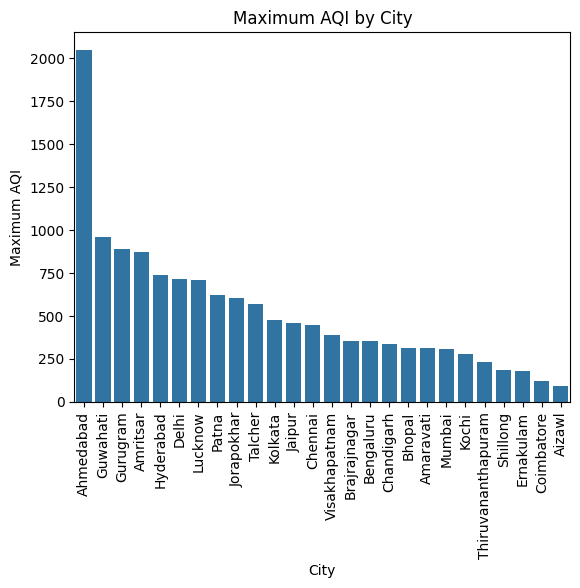

In [34]:
city_max_aqi = df.groupby("City")["AQI"].max().sort_values(ascending=False)
sns.barplot(x=city_max_aqi.index, y=city_max_aqi.values)
plt.xticks(rotation=90)
plt.xlabel("City")
plt.ylabel("Maximum AQI")
plt.title("Maximum AQI by City")
plt.show()

In [35]:
#Q6. During which months does air pollution become the worst?

In [36]:
df["Date"] = pd.to_datetime(df["Date"])
df["month"] = df["Date"].dt.month_name()
df["month_no"] = df["Date"].dt.month

In [37]:
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,month,month_no
0,Ahmedabad,2015-01-29,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,0.02,0.00,3.14,209.0,Poor,January,1
1,Ahmedabad,2015-01-30,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,0.04,0.00,4.81,328.0,Very Poor,January,1
2,Ahmedabad,2015-01-31,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,7.67,514.0,Severe,January,1
3,Ahmedabad,2015-02-01,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,25.87,782.0,Severe,February,2
4,Ahmedabad,2015-02-02,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,35.61,914.0,Severe,February,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24845,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good,June,6
24846,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory,June,6
24847,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory,June,6
24848,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory,June,6


In [38]:
worst_month=df.groupby(["month_no","month"])["AQI"].mean().sort_values(ascending=False).head(1)

In [39]:
worst_month

month_no  month   
11        November    241.681302
Name: AQI, dtype: float64

In [40]:
#Q7. Is air quality worse in winter than in summer?

In [41]:
Conditions=[
    df["month_no"].isin([12,1,2]),
    df["month_no"].isin([3,4,5]),
    df["month_no"].isin([6,7,8,9]),
    df["month_no"].isin([10,11])
]

In [42]:
choices=[
    "Winter",
    "Summer",
    "Monsoon",
    "Post monsoon"
]

In [43]:
df["Seasons"]=np.select(Conditions,choices,default="Unknown")

In [44]:
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,month,month_no,Seasons
0,Ahmedabad,2015-01-29,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,0.02,0.00,3.14,209.0,Poor,January,1,Winter
1,Ahmedabad,2015-01-30,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,0.04,0.00,4.81,328.0,Very Poor,January,1,Winter
2,Ahmedabad,2015-01-31,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,7.67,514.0,Severe,January,1,Winter
3,Ahmedabad,2015-02-01,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,25.87,782.0,Severe,February,2,Winter
4,Ahmedabad,2015-02-02,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,35.61,914.0,Severe,February,2,Winter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24845,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good,June,6,Monsoon
24846,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory,June,6,Monsoon
24847,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory,June,6,Monsoon
24848,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory,June,6,Monsoon


In [45]:
df.groupby("Seasons")["AQI"].mean().sort_values(ascending=False)

Seasons
Winter          220.610764
Post monsoon    215.473464
Summer          147.670392
Monsoon         115.555426
Name: AQI, dtype: float64

In [46]:
winter_vs_summer=df[df["Seasons"].isin(["Winter", "Summer"])].groupby("Seasons")["AQI"].mean()

In [47]:
winter_vs_summer

Seasons
Summer    147.670392
Winter    220.610764
Name: AQI, dtype: float64

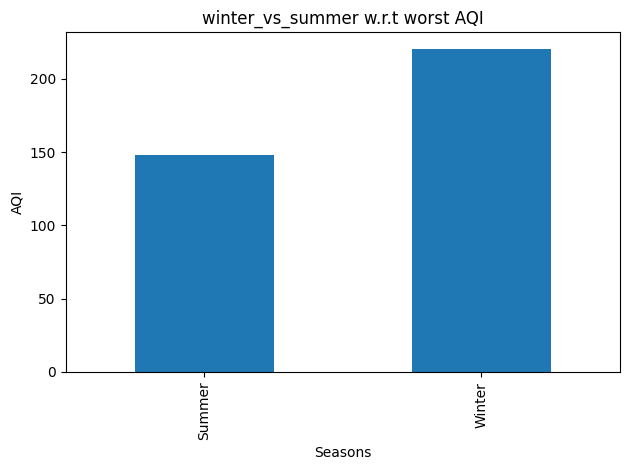

In [48]:
winter_vs_summer.plot(kind="bar")
plt.title("winter_vs_summer w.r.t worst AQI")
plt.ylabel("AQI")
plt.tight_layout()

In [49]:
#Q8. Which AQI category occurs most frequently?

In [50]:
df["AQI_Bucket"].value_counts()

AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

In [51]:
df["AQI_Bucket"].value_counts().idxmax()

'Moderate'

In [52]:
#Q9. Which cities have the most "Poor" or "Severe" AQI days?

In [53]:
poor_severe = df[df["AQI_Bucket"].isin(["Poor", "Severe"])]
city_counts = poor_severe.groupby("City").size().sort_values(ascending=False)
city_counts.head(10)

City
Ahmedabad       876
Delhi           781
Lucknow         462
Patna           410
Gurugram        405
Jorapokhar      139
Kolkata         132
Brajrajnagar    120
Chennai         116
Jaipur          112
dtype: int64

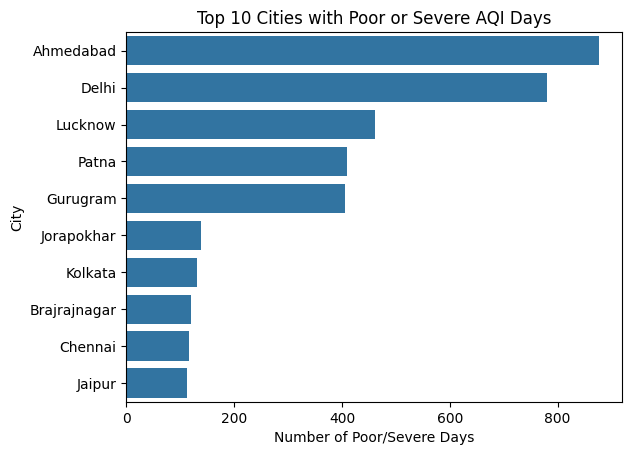

In [54]:
sns.barplot(x=city_counts.head(10).values,y=city_counts.head(10).index)
plt.xlabel("Number of Poor/Severe Days")
plt.ylabel("City")
plt.title("Top 10 Cities with Poor or Severe AQI Days")
plt.show()

In [55]:
#Q10. Which city has the most unpredictable air quality?

In [56]:
city_std = df.groupby("City")["AQI"].std().sort_values(ascending=False)
city_std.head(10)

City
Ahmedabad     311.729553
Patna         122.341700
Gurugram      119.943231
Delhi         119.537333
Lucknow       116.962788
Guwahati      112.755180
Talcher       104.867985
Kolkata       104.492533
Jorapokhar     84.698680
Amritsar       76.967676
Name: AQI, dtype: float64

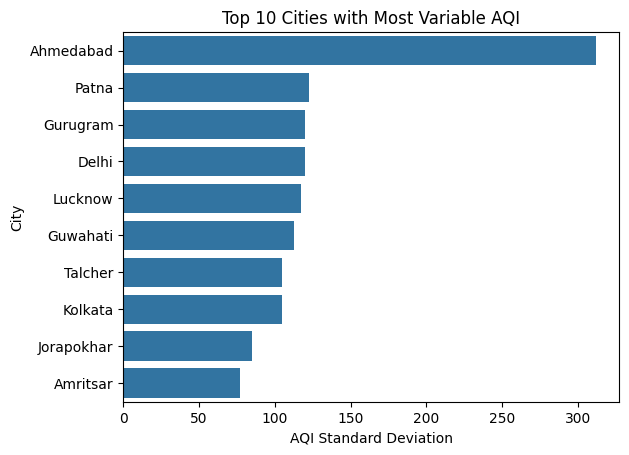

In [57]:
sns.barplot(x=city_std.head(10).values,y=city_std.head(10).index)
plt.xlabel("AQI Standard Deviation")
plt.ylabel("City")
plt.title("Top 10 Cities with Most Variable AQI")
plt.show()